<a href="https://colab.research.google.com/github/MNawfal24/MachineLearning/blob/main/Minggu2/MNawfalMA_JS05_T1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import hdbscan
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_digits
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score

# 1. Pilih dataset nyata (Digits Dataset)
digits = load_digits()
X = digits.data
y_true = digits.target

# Reduksi dimensi dengan t-SNE menjadi 2D
tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X)

print(f"Dimensi data awal: {X.shape}")
print(f"Dimensi data setelah t-SNE: {X_tsne.shape}")

Dimensi data awal: (1797, 64)
Dimensi data setelah t-SNE: (1797, 2)


In [2]:
# 2. clustering dengan HDBSCAN
# min_cluster_size diset 15 karena kita memperkirakan ada setidaknya 15 sampel per angka
hdb = hdbscan.HDBSCAN(min_cluster_size=15, min_samples=10).fit(X_tsne)
labels_hdb = hdb.labels_

# 3. Laporkan hasil: Jumlah cluster dan noise
n_clusters = len(set(labels_hdb)) - (1 if -1 in labels_hdb else 0)
n_noise = list(labels_hdb).count(-1)

print(f"Jumlah cluster yang terbentuk : {n_clusters}")
print(f"Banyaknya noise               : {n_noise}")

Jumlah cluster yang terbentuk : 13
Banyaknya noise               : 63


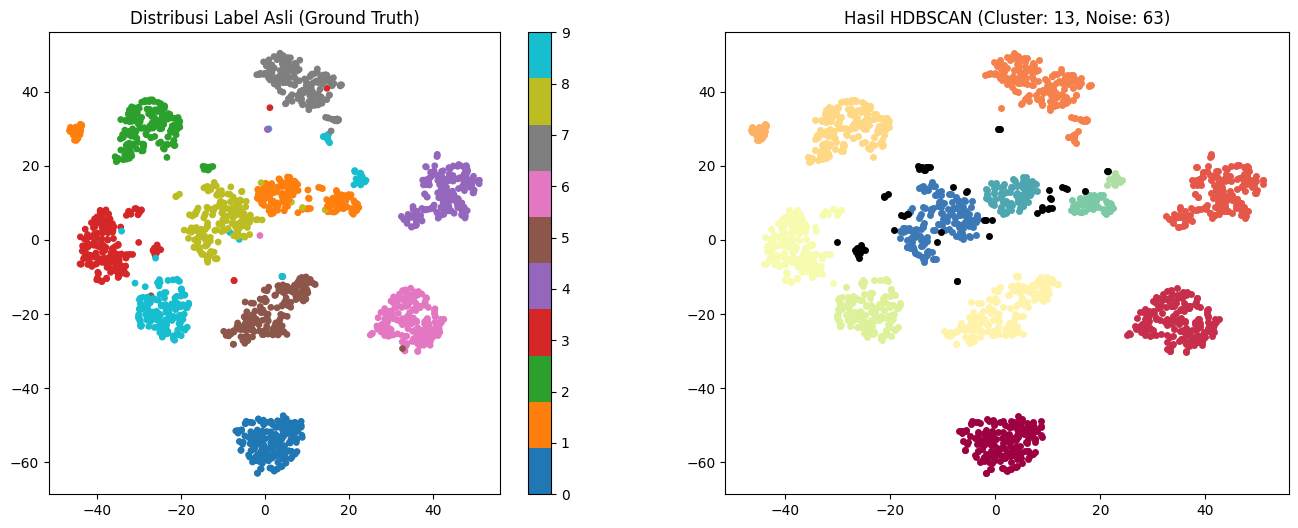

In [3]:
# 3. Visualisasi dengan hasil reduksi dimensi t-SNE
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# Plot berdasarkan Label Asli (Ground Truth)
scatter_true = ax[0].scatter(X_tsne[:, 0], X_tsne[:, 1], c=y_true, cmap='tab10', s=15)
ax[0].set_title("Distribusi Label Asli (Ground Truth)")
fig.colorbar(scatter_true, ax=ax[0], ticks=range(10))

# Plot berdasarkan Prediksi HDBSCAN
# Warna hitam disiapkan untuk noise (-1)
unique_labels = set(labels_hdb)
colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]

for k, col in zip(unique_labels, colors):
    if k == -1:
        col = [0, 0, 0, 1]  # Noise = Hitam

    class_member_mask = (labels_hdb == k)
    ax[1].plot(X_tsne[class_member_mask, 0], X_tsne[class_member_mask, 1], 'o',
             markerfacecolor=tuple(col), markeredgecolor='none', markersize=5)

ax[1].set_title(f"Hasil HDBSCAN (Cluster: {n_clusters}, Noise: {n_noise})")
plt.show()

In [4]:
# Menghitung Adjusted Rand Index (ARI) untuk perbandingan objektif
ari_score = adjusted_rand_score(y_true, labels_hdb)
print(f"Adjusted Rand Index (ARI) Score: {ari_score:.3f}")

Adjusted Rand Index (ARI) Score: 0.887
